# Step 3b: Provider-Level EDA & Statistical Tests

Provider-level EDA and formal statistical testing — the provider-level
counterpart to `03a_claim_level_eda.ipynb`. Combines what used to be two
separate notebooks:

1. **Statistical testing** (t-tests, chi-square/Cramér's V, Benford's Law,
   and the Extended Candidate Features significance/redundancy analysis)
   — this is where the 5 features now in `src/features.py`
   (`TopDiagnosisCodeShare`, `TopProcedureCodeShare`, `AvgPhysicianProviderSpread`,
   `TopBeneficiaryClaimShare`, `BenfordMAD`) were validated.
2. **Broader provider-level aggregation & EDA** — a 38-feature provider
   table built from `data/processed/claims_with_basic_features.csv`
   (`04a_basic_claim_level_feature_engineering.ipynb`'s output), explored
   across 12 topics: target distribution, claim volume, beneficiary
   activity, reimbursement, duration, diagnosis/procedure intensity,
   physician behavior, patient complexity, temporal behavior,
   repeated/suspicious claims, consolidated distributions, and feature
   relationships.

The missingness/distribution plots from the original `03_eda_stats.ipynb`
were dropped — they're superseded by `03a_claim_level_eda.ipynb`'s more
thorough claim-level coverage.

In [1]:
import sys
sys.path.append('..')

from src.data_loader import build_claim_level_dataset
from src.cleaning import clean_claim_level_dataset
from src.eda import *

df = clean_claim_level_dataset(build_claim_level_dataset())
provider_df = build_minimal_provider_summary(df)
df.shape, provider_df.shape

((558211, 61), (5410, 8))

## Fraud Group Comparisons: Boxplots

/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Non-Fraud", "Fraud"])
/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Non-Fraud", "Fraud"])
/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/notebooks/../src/eda.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Non-Fraud", "Fraud"])


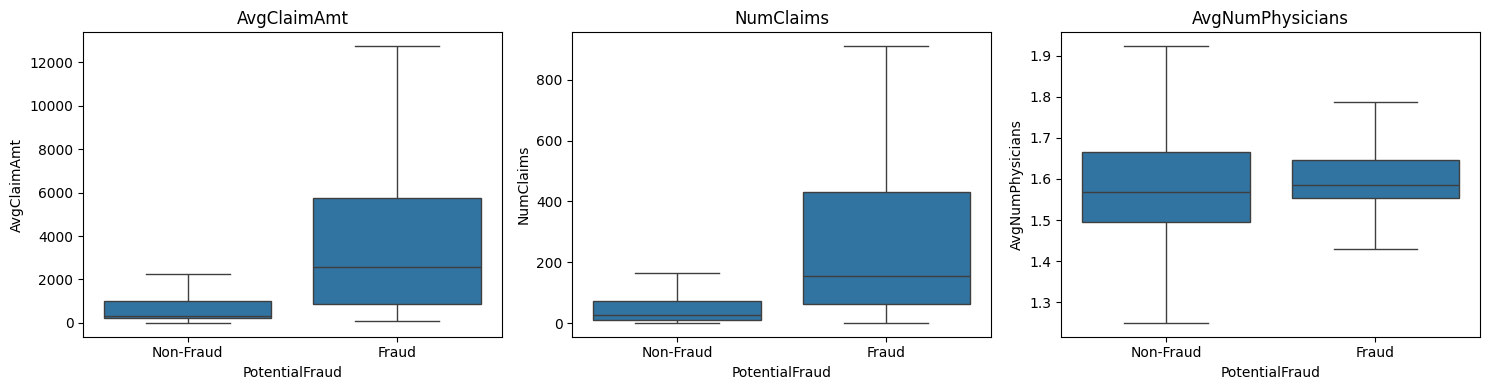

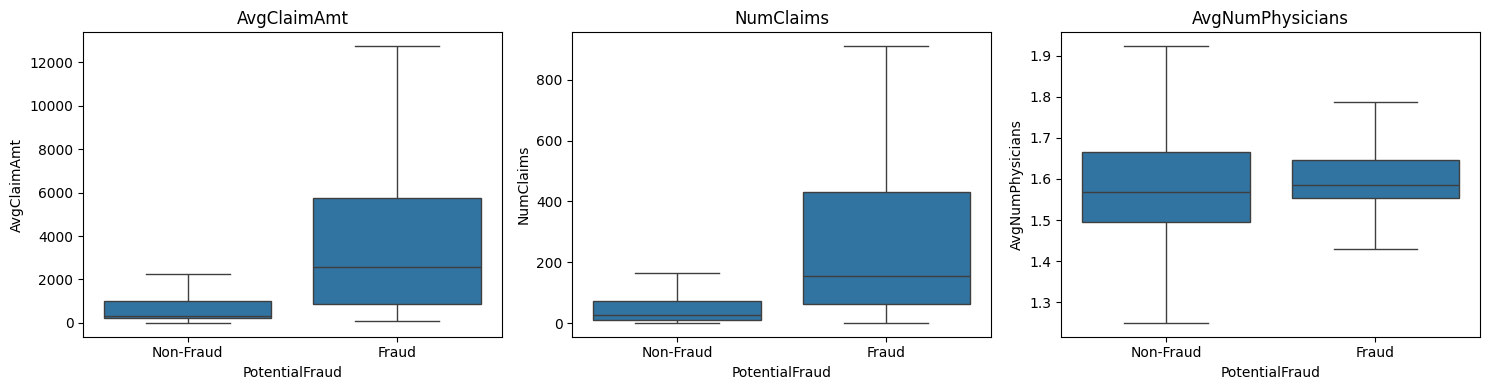

In [2]:
plot_fraud_boxplots(provider_df, ['AvgClaimAmt', 'NumClaims', 'AvgNumPhysicians'])

**What this shows:**
- **`AvgClaimAmt`:** the Fraud group's median and spread are visibly higher — fraudulent providers bill more per claim on average.
- **`NumClaims`:** same pattern, even more pronounced — the Fraud group's median claim count is roughly 3-4x higher, with a much wider spread.
- **`AvgNumPhysicians`:** nearly identical between groups — this feature doesn't discriminate fraud on its own. Worth keeping for now (it might interact with other features), but don't expect it to carry much weight alone.

## Correlation Heatmap

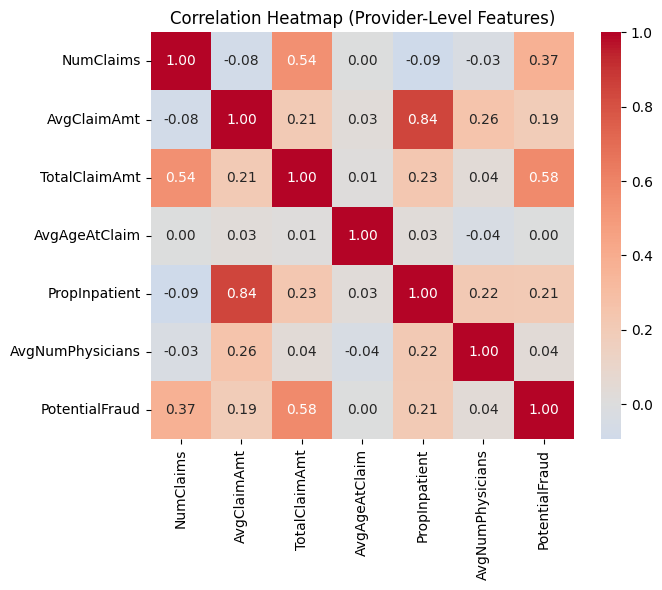

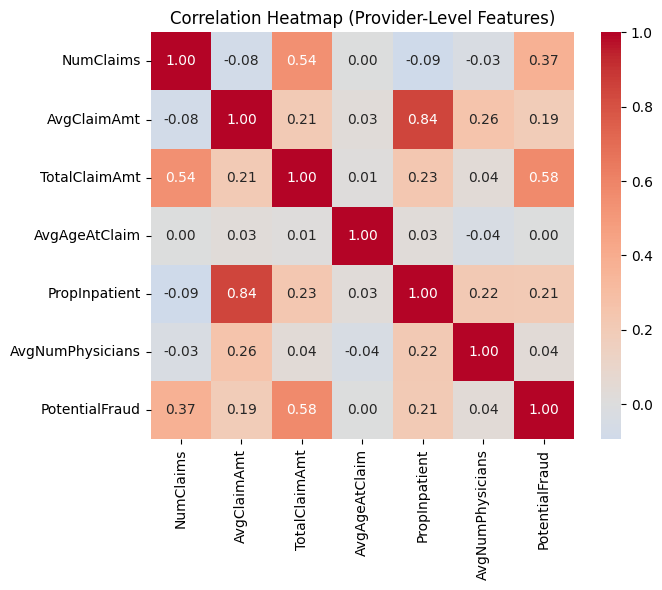

In [3]:
plot_correlation_heatmap(provider_df, ['NumClaims', 'AvgClaimAmt', 'TotalClaimAmt', 'AvgAgeAtClaim', 'PropInpatient', 'AvgNumPhysicians'])

**What this shows:**
- `TotalClaimAmt` correlates most strongly with fraud (**0.58**) — the strongest single linear signal so far.
- `NumClaims` also correlates meaningfully (**0.37**).
- `AvgClaimAmt` and `PropInpatient` correlate strongly *with each other* (**0.84**) — inpatient claims cost more per claim, so a provider doing more inpatient work naturally has a higher average claim amount. These two features carry overlapping information — worth watching for multicollinearity in Step 4/6 (e.g. if using logistic regression), or picking one over the other.
- `AvgAgeAtClaim` and `AvgNumPhysicians` are essentially uncorrelated with fraud (**0.00, 0.04**) — weak candidates as standalone features.

## Statistical Tests with Effect Sizes

P-values alone can be misleadingly "significant" at large sample sizes — effect size (`cohens_d`) tells us whether a difference is practically meaningful, not just statistically detectable. (The `ClaimType` chi-square/Cramér's V test and the Benford's Law comparison moved to `03a_claim_level_eda.ipynb`'s "Fraud-Rate Comparisons" section — they're computed on claim-level rows, not this section's provider-level `provider_df`.)

In [4]:
t_test(provider_df, 'AvgClaimAmt')

{'test': 'welch t-test',
 'column': 'AvgClaimAmt',
 't_statistic': np.float64(13.160882816164541),
 'p_value': np.float64(7.245998992198341e-35),
 'cohens_d': np.float64(0.6440568857690845),
 'mean_fraud': np.float64(3842.7951041423316),
 'mean_non_fraud': np.float64(1523.7808036833862)}

**How to read this:** `cohens_d` measures the size of the gap between Fraud and Non-Fraud group means, in standard-deviation units. As a rough guide: ~0.2 = small effect, ~0.5 = medium, ~0.8+ = large. Combine this with the boxplot above — a large `cohens_d` here would confirm what the boxplot already suggested visually.

In [5]:
t_test(provider_df, 'NumClaims')

{'test': 'welch t-test',
 'column': 'NumClaims',
 't_statistic': np.float64(10.879003597260029),
 'p_value': np.float64(6.352459016250494e-25),
 'cohens_d': np.float64(0.6744298899620966),
 'mean_fraud': np.float64(420.54545454545456),
 'mean_non_fraud': np.float64(70.43535889070147)}

**How to read this:** same interpretation as above, applied to claim volume instead of claim amount.

## Extended Candidate Features

The provider-level signals above (`AvgClaimAmt`, `NumClaims`, `ClaimType`,
Benford's Law) are what `src/features.py` already builds on. This section
tests a further batch of candidate signals — physician self-dealing,
billing "templating" (diagnosis/procedure/round-number concentration),
Benford's Law computed *per provider* rather than aggregated across the
whole Fraud/Non-Fraud group, and beneficiary-sharing/concentration
patterns — **before** deciding whether to add any of them to the feature
engineering pipeline in Step 4.

In [6]:
from src.feature_selection import evaluate_feature_significance, flag_weak_features
from src.features import build_provider_features

## Building the Candidate Feature Table

One row per provider. Each block below computes one candidate signal;
they're assembled into a single table at the end.

In [7]:
candidates = df[['Provider']].drop_duplicates().reset_index(drop=True)

### 1-2. Physician self-dealing & cross-provider sharing

In [8]:
# SameAttendingOperatingRate: share of claims where the same physician is
# listed as both attending and operating — a possible self-referral signal.
same_doc = (df['AttendingPhysician'] == df['OperatingPhysician']) & df['OperatingPhysician'].notna()
same_doc_rate = same_doc.groupby(df['Provider']).mean().rename('SameAttendingOperatingRate')

# AvgPhysicianProviderSpread: for each physician a provider uses (attending
# or operating role), how many DIFFERENT providers does that physician also
# bill under? Averaged per provider — high values mean this provider's
# physicians are shared with many other providers (a network/ring signal).
phys_long = pd.concat([
    df[['Provider', 'AttendingPhysician']].rename(columns={'AttendingPhysician': 'Physician'}),
    df[['Provider', 'OperatingPhysician']].rename(columns={'OperatingPhysician': 'Physician'}),
]).dropna()
phys_provider_count = phys_long.drop_duplicates().groupby('Physician')['Provider'].nunique()
phys_long['NumProvidersForPhysician'] = phys_long['Physician'].map(phys_provider_count)
avg_phys_spread = phys_long.groupby('Provider')['NumProvidersForPhysician'].mean().rename('AvgPhysicianProviderSpread')

candidates = candidates.merge(same_doc_rate, on='Provider').merge(avg_phys_spread, on='Provider')
candidates[['SameAttendingOperatingRate', 'AvgPhysicianProviderSpread']].describe()

,SameAttendingOperatingRate,AvgPhysicianProviderSpread
count,5410.000000,5410.000000
mean,0.138305,1.355211
std,0.154887,0.673826
min,0.000000,1.000000
25%,0.041667,1.000000
50%,0.108684,1.106667
75%,0.175439,1.379180
max,1.000000,8.733333


### 3-4. Diagnosis / procedure code "templating"

If a large share of a provider's claims use the *same* diagnosis or
procedure code, that looks more like copy-paste billing than genuine
clinical variety. Computed only among claims that have a code at all
(NaN means the provider has zero coded claims of that type — very common
for procedure codes, see the note below).

In [9]:
def top_code_share(s):
    s = s.dropna()
    return s.value_counts(normalize=True).iloc[0] if len(s) else np.nan

top_diag_share = df.groupby('Provider')['ClmDiagnosisCode_1'].apply(top_code_share).rename('TopDiagnosisCodeShare')
top_proc_share = df.groupby('Provider')['ClmProcedureCode_1'].apply(top_code_share).rename('TopProcedureCodeShare')

candidates = candidates.merge(top_diag_share, on='Provider').merge(top_proc_share, on='Provider')
print('Providers with zero coded claims (TopProcedureCodeShare is NaN):', candidates['TopProcedureCodeShare'].isna().sum(),
      f"({candidates['TopProcedureCodeShare'].isna().mean()*100:.1f}%)")
candidates[['TopDiagnosisCodeShare', 'TopProcedureCodeShare']].describe()

Providers with zero coded claims (TopProcedureCodeShare is NaN): 3386 (62.6%)


,TopDiagnosisCodeShare,TopProcedureCodeShare
count,5405.000000,2024.000000
mean,0.136247,0.379185
std,0.214435,0.328729
min,0.012500,0.027778
25%,0.034188,0.137762
50%,0.055556,0.250000
75%,0.125000,0.500000
max,1.000000,1.000000


### 5. Round-number billing rate

**Caveat found while prototyping this**: 45.7% of ALL claims in this dataset
(fraud and non-fraud alike) are already round to the nearest $100 — this
dataset's amounts are suspiciously round across the board (likely an
artifact of how the Kaggle dataset was generated), so a $100 threshold
barely discriminates anything. Using a stricter $1,000 threshold instead
(8.1% dataset-wide base rate) leaves more room for a real per-provider
signal to show through.

In [10]:
is_round = (df['InscClaimAmtReimbursed'] > 0) & (df['InscClaimAmtReimbursed'] % 1000 == 0)
round_rate = is_round.groupby(df['Provider']).mean().rename('RoundNumberClaimRate')
candidates = candidates.merge(round_rate, on='Provider')
candidates['RoundNumberClaimRate'].describe()

count    5410.000000
mean        0.148882
std         0.277489
min         0.000000
25%         0.000000
50%         0.015873
75%         0.139298
max         1.000000
Name: RoundNumberClaimRate, dtype: float64

### 6. Claim amount coefficient of variation

In [11]:
amt_stats = df.groupby('Provider')['InscClaimAmtReimbursed'].agg(['mean', 'std'])
claim_amt_cv = (amt_stats['std'] / amt_stats['mean']).fillna(0).rename('ClaimAmtCV')
candidates = candidates.merge(claim_amt_cv, on='Provider')
candidates['ClaimAmtCV'].describe()

count    5410.000000
mean        1.833566
std         0.934130
min         0.000000
25%         1.291126
50%         1.852363
75%         2.220892
max         7.509768
Name: ClaimAmtCV, dtype: float64

### 7. Per-provider Benford's Law deviation (MAD)

`benford_mean_absolute_deviation()` already exists in `src/eda.py` but has
only ever been run on the whole Fraud/Non-Fraud groups (Step 3) — never
per individual provider. Restricted to providers with **≥20 claims**, since
Benford's Law needs a reasonable sample to be meaningful; that excludes
2,090 providers (38.6%) who simply don't have enough claims to test.

In [12]:
claims_per_provider = df.groupby('Provider').size()
eligible_providers = claims_per_provider[claims_per_provider >= 20].index

benford_mad = (
    df[df['Provider'].isin(eligible_providers)]
    .groupby('Provider')['InscClaimAmtReimbursed']
    .apply(benford_mean_absolute_deviation)
    .rename('BenfordMAD')
)
candidates = candidates.merge(benford_mad, on='Provider', how='left')
print(f"Providers with a BenfordMAD value: {candidates['BenfordMAD'].notna().sum()} / {len(candidates)}")
candidates['BenfordMAD'].describe()

Providers with a BenfordMAD value: 3320 / 5410


count    3320.000000
mean        0.036415
std         0.015034
min         0.007569
25%         0.024902
50%         0.033558
75%         0.045198
max         0.105077
Name: BenfordMAD, dtype: float64

### 8-9. Beneficiary concentration & cross-provider sharing

In [13]:
# TopBeneficiaryClaimShare: does one "super-patient" account for an outsized
# share of this provider's claims?
bene_claim_counts = df.groupby(['Provider', 'BeneID']).size().reset_index(name='n')
top_bene_share = bene_claim_counts.groupby('Provider')['n'].apply(lambda x: x.max() / x.sum()).rename('TopBeneficiaryClaimShare')

# AvgBeneficiaryProviderSpread: on average, how many DIFFERENT providers do
# this provider's beneficiaries also visit? High values could indicate a
# shared patient pool across a ring of providers.
bene_dedup = df.drop_duplicates(subset=['Provider', 'BeneID'])
bene_provider_count = bene_dedup.groupby('BeneID')['Provider'].nunique()
bene_long = bene_dedup[['Provider', 'BeneID']].copy()
bene_long['NumProvidersForBene'] = bene_long['BeneID'].map(bene_provider_count)
avg_bene_spread = bene_long.groupby('Provider')['NumProvidersForBene'].mean().rename('AvgBeneficiaryProviderSpread')

candidates = candidates.merge(top_bene_share, on='Provider').merge(avg_bene_spread, on='Provider')
candidates[['TopBeneficiaryClaimShare', 'AvgBeneficiaryProviderSpread']].describe()

,TopBeneficiaryClaimShare,AvgBeneficiaryProviderSpread
count,5410.000000,5410.000000
mean,0.163094,3.941711
std,0.221413,1.077246
min,0.001942,1.000000
25%,0.040000,3.250000
50%,0.083333,3.939692
75%,0.176471,4.576528
max,1.000000,13.000000


### 10. Beneficiary geographic dispersion

In [14]:
geo_dispersion = bene_dedup.groupby('Provider')['State'].nunique().rename('NumUniqueBeneficiaryStates')
candidates = candidates.merge(geo_dispersion, on='Provider')
candidates['NumUniqueBeneficiaryStates'].describe()

count    5410.000000
mean        2.573198
std         3.053825
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        38.000000
Name: NumUniqueBeneficiaryStates, dtype: float64

### 11. Zero-reimbursement claim rate

In [15]:
zero_reimb_rate = (df['InscClaimAmtReimbursed'] == 0).groupby(df['Provider']).mean().rename('ZeroReimbursementRate')
candidates = candidates.merge(zero_reimb_rate, on='Provider')
candidates['ZeroReimbursementRate'].describe()

count    5410.000000
mean        0.038198
std         0.073780
min         0.000000
25%         0.000000
50%         0.026641
75%         0.047619
max         1.000000
Name: ZeroReimbursementRate, dtype: float64

### 12. Inpatient 30-day readmission rate

Only meaningful for providers with inpatient claims (2,092 of 5,410) —
readmission is inherently an inpatient concept.

In [16]:
inpatient = df[df['ClaimType'] == 'Inpatient'].copy().sort_values(['BeneID', 'AdmissionDt'])
inpatient['PrevDischarge'] = inpatient.groupby('BeneID')['DischargeDt'].shift(1)
inpatient['DaysSinceLastDischarge'] = (inpatient['AdmissionDt'] - inpatient['PrevDischarge']).dt.days
inpatient['IsReadmission'] = inpatient['DaysSinceLastDischarge'].between(0, 30)

readmit_rate = inpatient.groupby('Provider')['IsReadmission'].mean().rename('InpatientReadmissionRate')
candidates = candidates.merge(readmit_rate, on='Provider', how='left')
print(f"Providers with an InpatientReadmissionRate value: {candidates['InpatientReadmissionRate'].notna().sum()} / {len(candidates)}")
candidates['InpatientReadmissionRate'].describe()

Providers with an InpatientReadmissionRate value: 2092 / 5410


count    2092.000000
mean        0.063213
std         0.118404
min         0.000000
25%         0.000000
50%         0.000000
75%         0.090909
max         1.000000
Name: InpatientReadmissionRate, dtype: float64

## Attaching the Fraud Label & Ranking by Effect Size

Reusing `evaluate_feature_significance()` from `src/feature_selection.py` —
the same Cohen's d ranking used in Step 4 — so these candidates are judged
on the same terms as the features already in the model.

In [17]:
labels = pd.read_csv('../data/raw/provider_labels.csv')
labels['PotentialFraud'] = labels['PotentialFraud'].map({'Yes': 1, 'No': 0})
candidates = candidates.merge(labels, on='Provider', how='left')
candidates.shape

(5410, 14)

In [18]:
candidate_cols = [c for c in candidates.columns if c not in ('Provider', 'PotentialFraud')]
sig_df = evaluate_feature_significance(candidates, candidate_cols)
sig_df

,feature,mean_fraud,mean_non_fraud,t_statistic,p_value,cohens_d
0,TopProcedureCodeShare,0.185939,0.435066,-19.342403,7.725211e-73,-0.892854
1,TopBeneficiaryClaimShare,0.048289,0.174939,-27.446474,4.420957e-139,-0.747386
2,NumUniqueBeneficiaryStates,5.379447,2.283646,12.682297,2.333314e-32,0.731221
3,RoundNumberClaimRate,0.326635,0.130541,13.845410,6.276421e-38,0.681138
4,TopDiagnosisCodeShare,0.045563,0.145613,-24.866908,2.004603e-123,-0.617177
5,ClaimAmtCV,2.310836,1.784321,10.873938,3.270953e-25,0.536723
6,BenfordMAD,0.029927,0.037487,-11.388825,1.134366e-27,-0.536447
7,AvgPhysicianProviderSpread,1.140957,1.377318,-16.607815,9.964449e-58,-0.453943
8,ZeroReimbursementRate,0.031772,0.038861,-5.051210,4.680935e-07,-0.125888
9,AvgBeneficiaryProviderSpread,3.833792,3.952846,-3.201401,1.425509e-03,-0.125714


In [19]:
flagged = flag_weak_features(sig_df)
print('Weak candidates (small effect size or not significant):')
flagged[flagged['is_weak']][['feature', 'p_value', 'cohens_d']]

Weak candidates (small effect size or not significant):


,feature,p_value,cohens_d
8,ZeroReimbursementRate,4.680935e-07,-0.125888
9,AvgBeneficiaryProviderSpread,1.425509e-03,-0.125714
10,SameAttendingOperatingRate,4.750595e-03,-0.115191
11,InpatientReadmissionRate,1.996477e-01,0.056176


## Visual Check on the Strongest Candidates

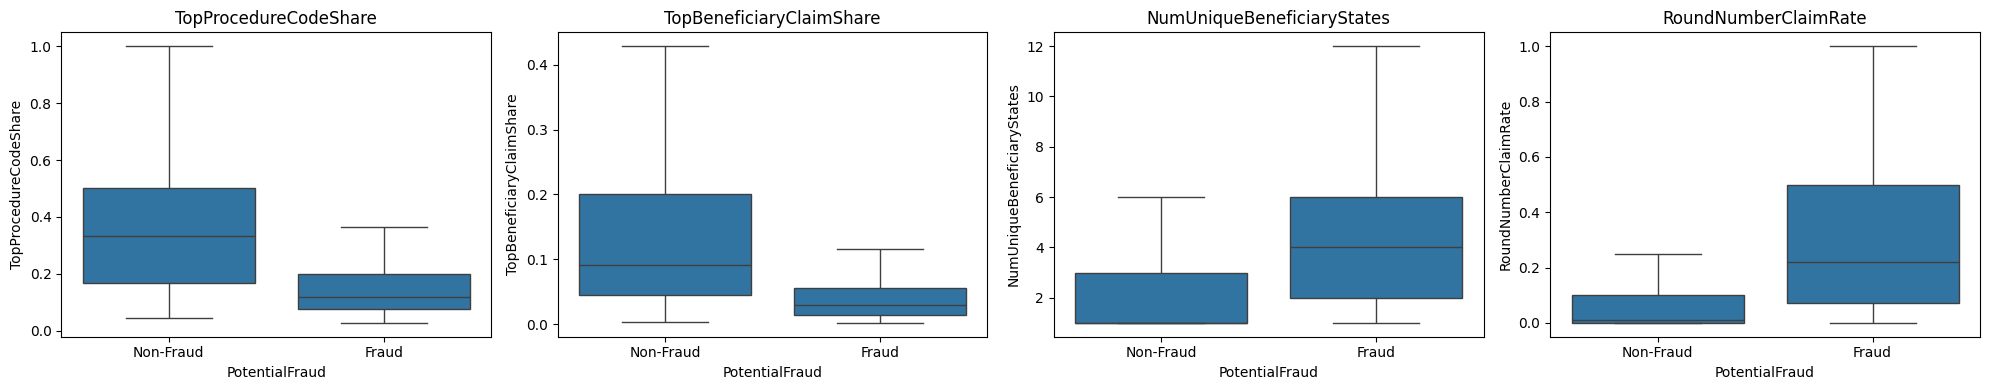

In [20]:
top_candidates = sig_df.head(4)['feature'].tolist()
fig, axes = plt.subplots(1, len(top_candidates), figsize=(5 * len(top_candidates), 4))
for ax, col in zip(axes, top_candidates):
    sns.boxplot(data=candidates, x='PotentialFraud', y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Non-Fraud', 'Fraud'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Redundancy Check Against Existing Features

Before recommending any of these for `src/features.py`, check they aren't
just re-measuring something `build_provider_features()` already captures
(e.g. `AvgPhysicianProviderSpread` vs. `NumUniqueAttendingPhysicians`).

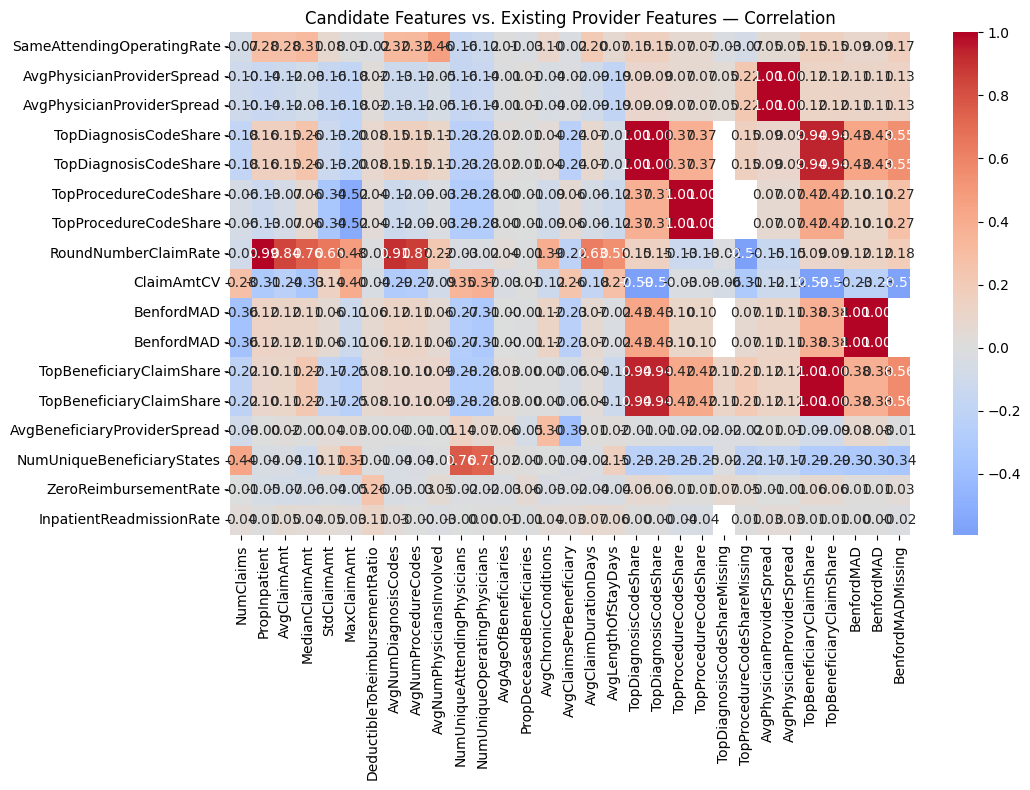

In [21]:
from src.features import build_provider_features

existing_features = build_provider_features(df)
merged_check = candidates.merge(existing_features, on='Provider', suffixes=('', '_existing'))

existing_cols = [c for c in existing_features.columns if c not in ('Provider', 'PotentialFraud')]
corr_matrix = merged_check[candidate_cols + existing_cols].corr()
cross_corr = corr_matrix.loc[candidate_cols, existing_cols]

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(cross_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Candidate Features vs. Existing Provider Features — Correlation')
plt.tight_layout()
plt.show()

## Broader Provider-Level Aggregation & EDA

Everything above used the minimal 6-column `provider_df` (from
`build_minimal_provider_summary()`) or the 12-column `candidates` table.
This section builds a much richer, 38-feature provider table directly from
`claims_with_basic_features.csv` and explores it across 12 topics. Loads a
second data source (the claim-level table with `04a`'s features already
attached) since it's built from a different, richer starting point than
`df` above.

In [22]:
from src.data_loader import RAW_DATA_DIR

claims = pd.read_csv('../data/processed/claims_with_basic_features.csv', low_memory=False)
claims.shape

(558211, 86)

## Provider-Level Aggregation

In [23]:
# --- Claim volume ---
volume = claims.groupby('Provider').agg(
    NumClaims=('ClaimID', 'count'),
    NumInpatientClaims=('IsInpatient', 'sum'),
).reset_index()
volume['NumOutpatientClaims'] = volume['NumClaims'] - volume['NumInpatientClaims']
volume['PropInpatient'] = volume['NumInpatientClaims'] / volume['NumClaims']
volume.describe()

,NumClaims,NumInpatientClaims,NumOutpatientClaims,PropInpatient
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,103.181331,7.481331,95.700000,0.144568
std,272.456989,23.704217,266.520526,0.288362
min,1.000000,0.000000,0.000000,0.000000
25%,10.000000,0.000000,7.000000,0.000000
50%,31.000000,0.000000,27.000000,0.000000
75%,87.000000,5.000000,77.000000,0.128205
max,8240.000000,516.000000,8240.000000,1.000000


In [24]:
# --- Beneficiary activity ---
bene_counts = claims.groupby(['Provider', 'BeneID']).size().reset_index(name='NumClaimsFromBene')
beneficiary = bene_counts.groupby('Provider').agg(
    NumUniqueBeneficiaries=('BeneID', 'nunique'),
).reset_index()
repeat_rate = bene_counts.groupby('Provider')['NumClaimsFromBene'].apply(lambda x: (x > 1).mean())
beneficiary['RepeatBeneficiaryRate'] = beneficiary['Provider'].map(repeat_rate)
beneficiary = beneficiary.merge(volume[['Provider', 'NumClaims']], on='Provider')
beneficiary['ClaimsPerBeneficiary'] = beneficiary['NumClaims'] / beneficiary['NumUniqueBeneficiaries']
beneficiary = beneficiary.drop(columns='NumClaims')
beneficiary.describe()

,NumUniqueBeneficiaries,RepeatBeneficiaryRate,ClaimsPerBeneficiary
count,5410.000000,5410.000000,5410.000000
mean,67.153420,0.157540,1.326886
std,142.748729,0.186006,0.535671
min,1.000000,0.000000,1.000000
25%,8.000000,0.000000,1.000000
50%,25.000000,0.083333,1.098784
75%,65.000000,0.250000,1.400000
max,2857.000000,1.000000,10.000000


In [25]:
# --- Reimbursement behaviour ---
reimbursement = claims.groupby('Provider')['InscClaimAmtReimbursed'].agg(
    TotalReimbursement='sum', MeanReimbursement='mean', MedianReimbursement='median',
    MaxReimbursement='max', StdReimbursement='std',
).reset_index()
reimbursement['StdReimbursement'] = reimbursement['StdReimbursement'].fillna(0)
reimbursement = reimbursement.merge(beneficiary[['Provider', 'NumUniqueBeneficiaries']], on='Provider')
reimbursement['ReimbursementPerBeneficiary'] = reimbursement['TotalReimbursement'] / reimbursement['NumUniqueBeneficiaries']
reimbursement = reimbursement.drop(columns='NumUniqueBeneficiaries')
reimbursement.describe()

,TotalReimbursement,MeanReimbursement,MedianReimbursement,MaxReimbursement,StdReimbursement,ReimbursementPerBeneficiary
count,5.410000e+03,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000
mean,1.028730e+05,1740.679369,928.602588,13014.913124,2424.047650,1972.142621
std,2.687367e+05,3484.473124,2977.988601,18995.317219,3649.238968,3709.701512
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.460000e+03,232.394593,70.000000,1700.000000,392.741485,286.922057
50%,1.980500e+04,356.085106,85.000000,3300.000000,674.251609,543.282504
75%,8.556500e+04,1490.154301,100.000000,17000.000000,3400.482846,1902.357143
max,5.996050e+06,57000.000000,57000.000000,125000.000000,50204.581464,75000.000000


In [26]:
# --- Claim duration ---
duration = claims.groupby('Provider').agg(
    MeanClaimDuration=('ClaimDuration', 'mean'),
    MaxClaimDuration=('ClaimDuration', 'max'),
    SameDayClaimRate=('SameDayClaim', 'mean'),
).reset_index()
los = claims[claims['IsInpatient'] == 1].groupby('Provider')['LengthOfStay'].mean().rename('MeanLengthOfStay')
duration = duration.merge(los, on='Provider', how='left')
duration['MeanLengthOfStay'] = duration['MeanLengthOfStay'].fillna(0)
duration.describe()

,MeanClaimDuration,MaxClaimDuration,SameDayClaimRate,MeanLengthOfStay
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,2.013987,16.185767,0.752802,2.190740
std,2.057721,9.227715,0.268122,3.249546
min,0.000000,0.000000,0.000000,0.000000
25%,0.875000,9.250000,0.722436,0.000000
50%,1.586207,20.000000,0.846154,0.000000
75%,2.544613,20.000000,0.903226,4.666667
max,35.000000,36.000000,1.000000,35.000000


In [27]:
# --- Diagnosis & procedure intensity ---
diag_proc = claims.groupby('Provider').agg(
    MeanNumDiagnosisCodes=('NumDiagnosisCodes', 'mean'),
    MaxNumDiagnosisCodes=('NumDiagnosisCodes', 'max'),
    MeanNumProcedureCodes=('NumProcedureCodes', 'mean'),
    MaxNumProcedureCodes=('NumProcedureCodes', 'max'),
    MeanClaimComplexity=('ClaimComplexity', 'mean'),
    NumUniqueDiagnosisCodes=('PrimaryDiagnosis', 'nunique'),
    NumUniqueProcedureCodes=('ClmProcedureCode_1', 'nunique'),
).reset_index()
diag_proc.describe()

,MeanNumDiagnosisCodes,MaxNumDiagnosisCodes,MeanNumProcedureCodes,MaxNumProcedureCodes,MeanClaimComplexity,NumUniqueDiagnosisCodes,NumUniqueProcedureCodes
count,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000
mean,3.407356,8.150277,0.108011,0.750277,3.515366,81.590018,3.549168
std,1.727429,2.322526,0.246305,1.110266,1.932527,164.728484,9.479985
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.500000,8.000000,0.000000,0.000000,2.500000,9.000000,0.000000
50%,2.814550,9.000000,0.000000,0.000000,2.826087,29.000000,0.000000
75%,3.567646,10.000000,0.083333,2.000000,3.666667,80.000000,3.000000
max,10.000000,10.000000,3.000000,5.000000,11.000000,3070.000000,146.000000


In [28]:
# --- Physician behaviour ---
phys_long = pd.concat([
    claims[['Provider', 'AttendingPhysician']].rename(columns={'AttendingPhysician': 'Physician'}),
    claims[['Provider', 'OperatingPhysician']].rename(columns={'OperatingPhysician': 'Physician'}),
    claims[['Provider', 'OtherPhysician']].rename(columns={'OtherPhysician': 'Physician'}),
]).dropna()
physician = phys_long.groupby('Provider')['Physician'].nunique().reset_index(name='NumUniquePhysicians')
physician = physician.merge(volume[['Provider', 'NumClaims']], on='Provider')
physician['ClaimsPerPhysician'] = physician['NumClaims'] / physician['NumUniquePhysicians']
physician = physician.drop(columns='NumClaims')

top_phys_share = claims.groupby(['Provider', 'AttendingPhysician']).size().reset_index(name='n')
top_phys_share = top_phys_share.groupby('Provider')['n'].apply(lambda x: x.max() / x.sum())
physician['TopPhysicianClaimShare'] = physician['Provider'].map(top_phys_share)

op_rate = claims.groupby('Provider')['HasOperatingPhysician'].mean().rename('OperatingPhysicianRate')
physician = physician.merge(op_rate, on='Provider')
physician.describe()

,NumUniquePhysicians,ClaimsPerPhysician,TopPhysicianClaimShare,OperatingPhysicianRate
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,20.210536,14.547977,0.453805,0.236900
std,36.228770,54.840311,0.328602,0.187408
min,1.000000,0.333333,0.017462,0.000000
25%,2.000000,1.400000,0.173229,0.142857
50%,7.000000,2.606061,0.344262,0.196721
75%,23.000000,8.000000,0.700000,0.275862
max,735.000000,1177.142857,1.000000,1.000000


In [29]:
# --- Patient complexity (deduplicated to Provider-Beneficiary to avoid
# over-weighting frequently-visiting patients) ---
unique_bene = claims.drop_duplicates(subset=['Provider', 'BeneID'])
patient_complexity = unique_bene.groupby('Provider').agg(
    MeanAge=('AgeAtClaim', 'mean'),
    MeanChronicConditions=('NumChronicConditions', 'mean'),
    RenalDiseaseRate=('HasRenalDisease', 'mean'),
).reset_index()
patient_complexity.describe()

,MeanAge,MeanChronicConditions,RenalDiseaseRate
count,5410.000000,5410.000000,5410.000000
mean,73.205119,4.425597,0.187804
std,4.555640,0.884788,0.141780
min,33.338809,0.000000,0.000000
25%,71.373220,4.000000,0.125000
50%,73.291757,4.375000,0.176471
75%,75.089389,4.800000,0.229167
max,99.728953,10.000000,1.000000


In [30]:
# --- Temporal behaviour ---
temporal = claims.groupby('Provider').agg(
    WeekendClaimRate=('IsWeekend', 'mean'),
    NumActiveMonths=('ClaimMonth', 'nunique'),
).reset_index()
claims_per_date = claims.groupby(['Provider', 'ClaimStartDt']).size().reset_index(name='n')
active_days = claims_per_date.groupby('Provider').agg(
    NumActiveDays=('ClaimStartDt', 'nunique'),
    MaxClaimsPerDay=('n', 'max'),
).reset_index()
temporal = temporal.merge(active_days, on='Provider')
temporal = temporal.merge(volume[['Provider', 'NumClaims']], on='Provider')
temporal['ClaimsPerActiveDay'] = temporal['NumClaims'] / temporal['NumActiveDays']
temporal = temporal.drop(columns=['NumClaims', 'NumActiveDays'])
temporal.describe()

,WeekendClaimRate,NumActiveMonths,MaxClaimsPerDay,ClaimsPerActiveDay
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,0.287415,9.189649,2.233457,1.174430
std,0.156220,3.622852,1.930774,0.598542
min,0.000000,1.000000,1.000000,1.000000
25%,0.228070,7.000000,1.000000,1.000000
50%,0.284211,11.000000,2.000000,1.045455
75%,0.333333,12.000000,3.000000,1.140845
max,1.000000,12.000000,41.000000,21.627297


In [31]:
# --- Repeated / suspicious claims ---
repeated = claims.groupby('Provider').agg(
    SameBeneProviderDayRate=('SameBeneProviderDay', 'mean'),
    ClaimWithin7DaysRate=('ClaimWithin7Days', 'mean'),
    ClaimWithin30DaysRate=('ClaimWithin30Days', 'mean'),
).reset_index()
repeated.describe()

,SameBeneProviderDayRate,ClaimWithin7DaysRate,ClaimWithin30DaysRate
count,5410.000000,5410.000000,5410.000000
mean,0.002081,0.108509,0.340272
std,0.009895,0.111880,0.168619
min,0.000000,0.000000,0.000000
25%,0.000000,0.050000,0.272727
50%,0.000000,0.101449,0.341679
75%,0.000000,0.137586,0.401764
max,0.285714,1.000000,1.000000


In [32]:
# --- Assemble the full provider table + fraud label ---
blocks = [volume, beneficiary, reimbursement, duration, diag_proc, physician, patient_complexity, temporal, repeated]
provider_features = blocks[0]
for block in blocks[1:]:
    provider_features = provider_features.merge(block, on='Provider', how='left')

labels = pd.read_csv(RAW_DATA_DIR / 'provider_labels.csv')
labels['PotentialFraud'] = labels['PotentialFraud'].map({'Yes': 1, 'No': 0})
provider_features = provider_features.merge(labels, on='Provider', how='left')

provider_features.to_csv('../data/processed/provider_level_eda_table.csv', index=False)
provider_features.shape

(5410, 40)

*One row per provider (5,410), 33 engineered columns + `PotentialFraud`. Saved to `data/processed/provider_level_eda_table.csv`.*

In [33]:
def fraud_boxplots(cols, ncols=None):
    ncols = ncols or len(cols)
    fig, axes = plt.subplots(1, ncols, figsize=(4.5 * ncols, 4))
    if ncols == 1:
        axes = [axes]
    for ax, col in zip(axes, cols):
        sns.boxplot(data=provider_features, x='PotentialFraud', y=col, ax=ax, showfliers=False)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Non-Fraud', 'Fraud'])
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

## 1. Target Distribution

In [34]:
counts = provider_features['PotentialFraud'].value_counts()
pct = provider_features['PotentialFraud'].value_counts(normalize=True).round(4)
print(counts)
print(pct)

PotentialFraud
0    4904
1     506
Name: count, dtype: int64
PotentialFraud
0    0.9065
1    0.0935
Name: proportion, dtype: float64


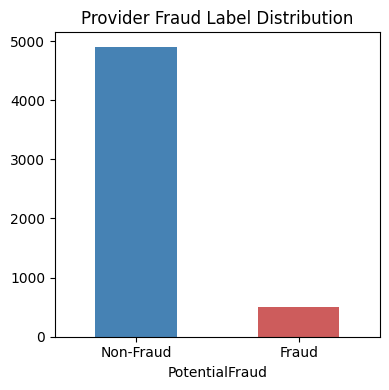

In [35]:
counts.plot(kind='bar', color=['steelblue', 'indianred'], figsize=(4, 4))
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'], rotation=0)
plt.title('Provider Fraud Label Distribution')
plt.tight_layout()
plt.show()

*9.35% of providers are labeled fraudulent — the core class imbalance every downstream model has to handle.*

## 2. Claim Volume

In [36]:
provider_features[['NumClaims', 'NumInpatientClaims', 'NumOutpatientClaims', 'PropInpatient']].describe()

,NumClaims,NumInpatientClaims,NumOutpatientClaims,PropInpatient
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,103.181331,7.481331,95.700000,0.144568
std,272.456989,23.704217,266.520526,0.288362
min,1.000000,0.000000,0.000000,0.000000
25%,10.000000,0.000000,7.000000,0.000000
50%,31.000000,0.000000,27.000000,0.000000
75%,87.000000,5.000000,77.000000,0.128205
max,8240.000000,516.000000,8240.000000,1.000000


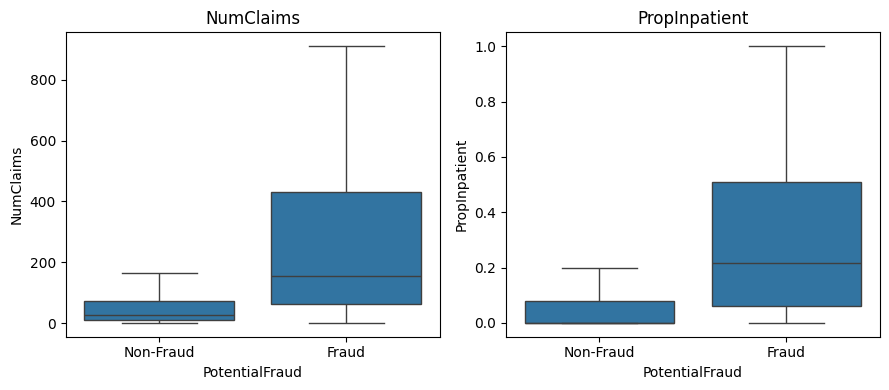

In [37]:
fraud_boxplots(['NumClaims', 'PropInpatient'])

*Fraud providers show visibly higher claim counts and a higher inpatient share — matches the statistical testing findings above.*

## 3. Beneficiary Activity

In [38]:
provider_features[['NumUniqueBeneficiaries', 'ClaimsPerBeneficiary', 'RepeatBeneficiaryRate']].describe()

,NumUniqueBeneficiaries,ClaimsPerBeneficiary,RepeatBeneficiaryRate
count,5410.000000,5410.000000,5410.000000
mean,67.153420,1.326886,0.157540
std,142.748729,0.535671,0.186006
min,1.000000,1.000000,0.000000
25%,8.000000,1.000000,0.000000
50%,25.000000,1.098784,0.083333
75%,65.000000,1.400000,0.250000
max,2857.000000,10.000000,1.000000


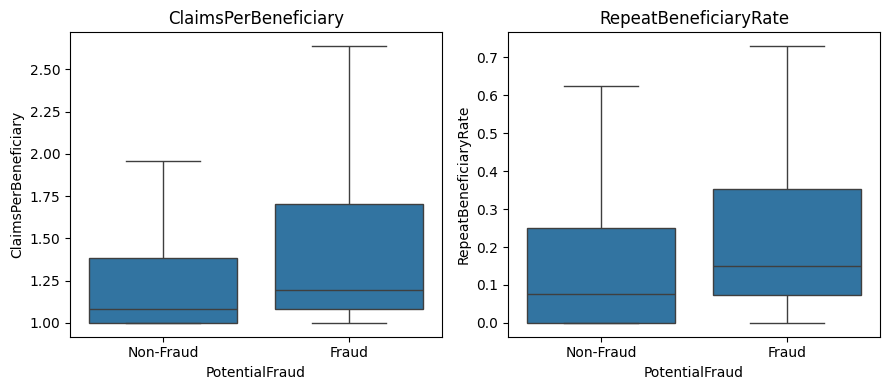

In [39]:
fraud_boxplots(['ClaimsPerBeneficiary', 'RepeatBeneficiaryRate'])

*Watch the direction here against the Extended Candidate Features section above — `TopBeneficiaryClaimShare` there found fraud providers depend LESS on repeat patients, so check whether `RepeatBeneficiaryRate` (a different, coarser measure) agrees or conflicts.*

## 4. Reimbursement Behaviour

In [40]:
provider_features[['TotalReimbursement', 'MeanReimbursement', 'MedianReimbursement', 'MaxReimbursement', 'StdReimbursement', 'ReimbursementPerBeneficiary']].describe()

,TotalReimbursement,MeanReimbursement,MedianReimbursement,MaxReimbursement,StdReimbursement,ReimbursementPerBeneficiary
count,5.410000e+03,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000
mean,1.028730e+05,1740.679369,928.602588,13014.913124,2424.047650,1972.142621
std,2.687367e+05,3484.473124,2977.988601,18995.317219,3649.238968,3709.701512
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.460000e+03,232.394593,70.000000,1700.000000,392.741485,286.922057
50%,1.980500e+04,356.085106,85.000000,3300.000000,674.251609,543.282504
75%,8.556500e+04,1490.154301,100.000000,17000.000000,3400.482846,1902.357143
max,5.996050e+06,57000.000000,57000.000000,125000.000000,50204.581464,75000.000000


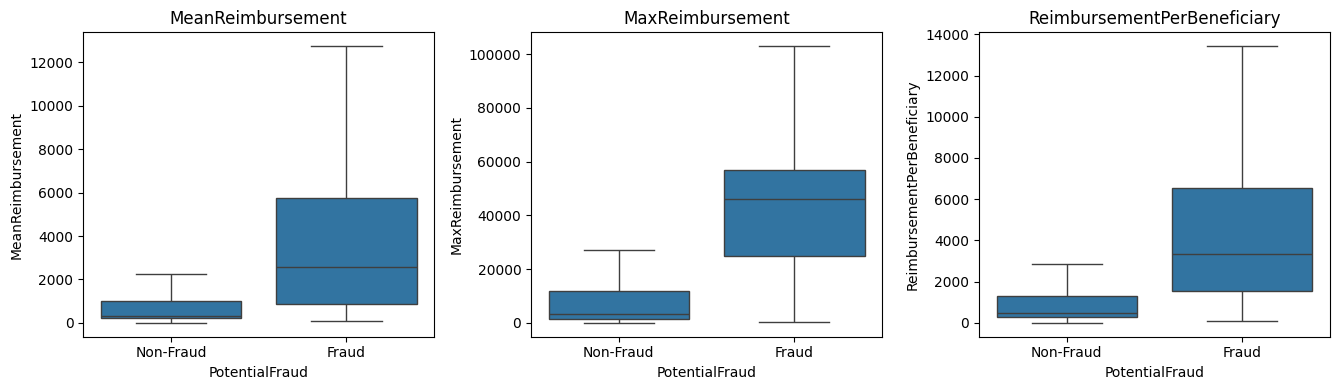

In [41]:
fraud_boxplots(['MeanReimbursement', 'MaxReimbursement', 'ReimbursementPerBeneficiary'])

*Fraud providers bill more in total and per beneficiary — consistent with claim volume being the strongest known signal.*

## 5. Claim Duration

In [42]:
provider_features[['MeanClaimDuration', 'MaxClaimDuration', 'SameDayClaimRate', 'MeanLengthOfStay']].describe()

,MeanClaimDuration,MaxClaimDuration,SameDayClaimRate,MeanLengthOfStay
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,2.013987,16.185767,0.752802,2.190740
std,2.057721,9.227715,0.268122,3.249546
min,0.000000,0.000000,0.000000,0.000000
25%,0.875000,9.250000,0.722436,0.000000
50%,1.586207,20.000000,0.846154,0.000000
75%,2.544613,20.000000,0.903226,4.666667
max,35.000000,36.000000,1.000000,35.000000


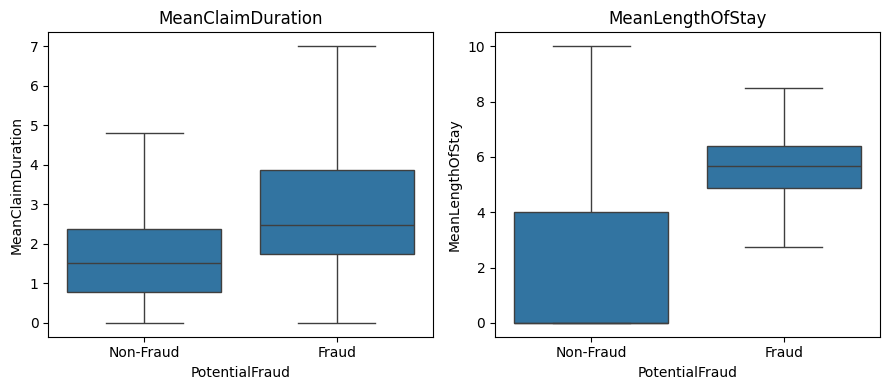

In [43]:
fraud_boxplots(['MeanClaimDuration', 'MeanLengthOfStay'])

*`MeanLengthOfStay` in particular separates the groups — inpatient stays run longer for fraud providers on average.*

## 6. Diagnosis & Procedure Intensity

In [44]:
provider_features[['MeanNumDiagnosisCodes', 'MaxNumDiagnosisCodes', 'MeanNumProcedureCodes',
             'MaxNumProcedureCodes', 'MeanClaimComplexity', 'NumUniqueDiagnosisCodes', 'NumUniqueProcedureCodes']].describe()

,MeanNumDiagnosisCodes,MaxNumDiagnosisCodes,MeanNumProcedureCodes,MaxNumProcedureCodes,MeanClaimComplexity,NumUniqueDiagnosisCodes,NumUniqueProcedureCodes
count,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000,5410.000000
mean,3.407356,8.150277,0.108011,0.750277,3.515366,81.590018,3.549168
std,1.727429,2.322526,0.246305,1.110266,1.932527,164.728484,9.479985
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.500000,8.000000,0.000000,0.000000,2.500000,9.000000,0.000000
50%,2.814550,9.000000,0.000000,0.000000,2.826087,29.000000,0.000000
75%,3.567646,10.000000,0.083333,2.000000,3.666667,80.000000,3.000000
max,10.000000,10.000000,3.000000,5.000000,11.000000,3070.000000,146.000000


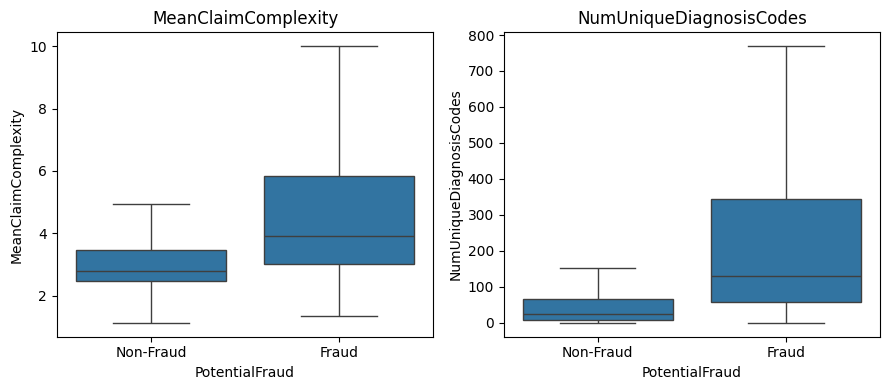

In [45]:
fraud_boxplots(['MeanClaimComplexity', 'NumUniqueDiagnosisCodes'])

*Fraud providers code more intensely per claim on average, but also use a wider variety of codes overall — coding volume and coding diversity both trend up.*

## 7. Physician Behaviour

In [46]:
provider_features[['NumUniquePhysicians', 'ClaimsPerPhysician', 'TopPhysicianClaimShare', 'OperatingPhysicianRate']].describe()

,NumUniquePhysicians,ClaimsPerPhysician,TopPhysicianClaimShare,OperatingPhysicianRate
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,20.210536,14.547977,0.453805,0.236900
std,36.228770,54.840311,0.328602,0.187408
min,1.000000,0.333333,0.017462,0.000000
25%,2.000000,1.400000,0.173229,0.142857
50%,7.000000,2.606061,0.344262,0.196721
75%,23.000000,8.000000,0.700000,0.275862
max,735.000000,1177.142857,1.000000,1.000000


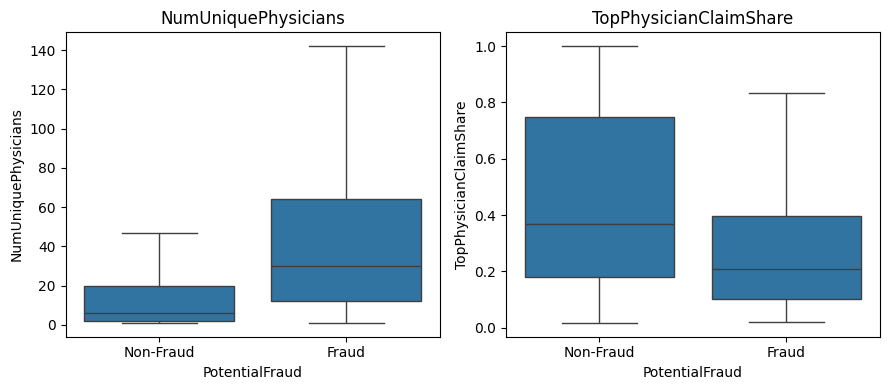

In [47]:
fraud_boxplots(['NumUniquePhysicians', 'TopPhysicianClaimShare'])

*Fraud providers work with more distinct physicians in absolute terms — check `ClaimsPerPhysician` and `TopPhysicianClaimShare` against the Extended Candidate Features section's `AvgPhysicianProviderSpread`/`NumUniqueAttendingPhysicians` above for overlap before treating this as new information.*

## 8. Patient Complexity

In [48]:
provider_features[['MeanAge', 'MeanChronicConditions', 'RenalDiseaseRate']].describe()

,MeanAge,MeanChronicConditions,RenalDiseaseRate
count,5410.000000,5410.000000,5410.000000
mean,73.205119,4.425597,0.187804
std,4.555640,0.884788,0.141780
min,33.338809,0.000000,0.000000
25%,71.373220,4.000000,0.125000
50%,73.291757,4.375000,0.176471
75%,75.089389,4.800000,0.229167
max,99.728953,10.000000,1.000000


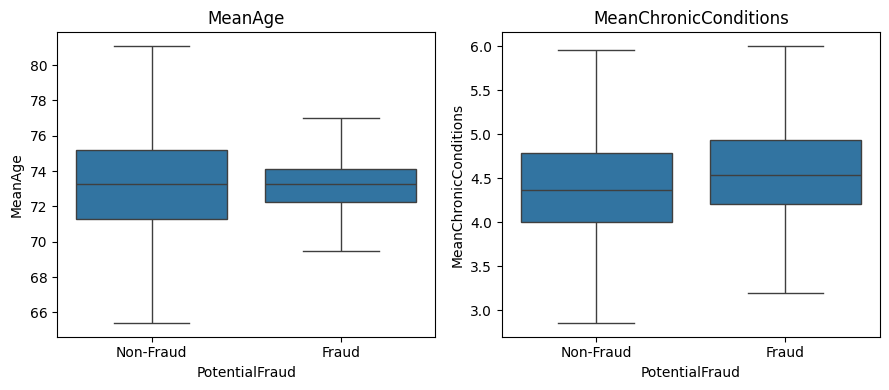

In [49]:
fraud_boxplots(['MeanAge', 'MeanChronicConditions'])

*If fraud providers' patients aren't meaningfully older/sicker, higher billing can't be explained away by genuine case complexity.*

## 9. Temporal Behaviour

In [50]:
provider_features[['WeekendClaimRate', 'NumActiveMonths', 'ClaimsPerActiveDay', 'MaxClaimsPerDay']].describe()

,WeekendClaimRate,NumActiveMonths,ClaimsPerActiveDay,MaxClaimsPerDay
count,5410.000000,5410.000000,5410.000000,5410.000000
mean,0.287415,9.189649,1.174430,2.233457
std,0.156220,3.622852,0.598542,1.930774
min,0.000000,1.000000,1.000000,1.000000
25%,0.228070,7.000000,1.000000,1.000000
50%,0.284211,11.000000,1.045455,2.000000
75%,0.333333,12.000000,1.140845,3.000000
max,1.000000,12.000000,21.627297,41.000000


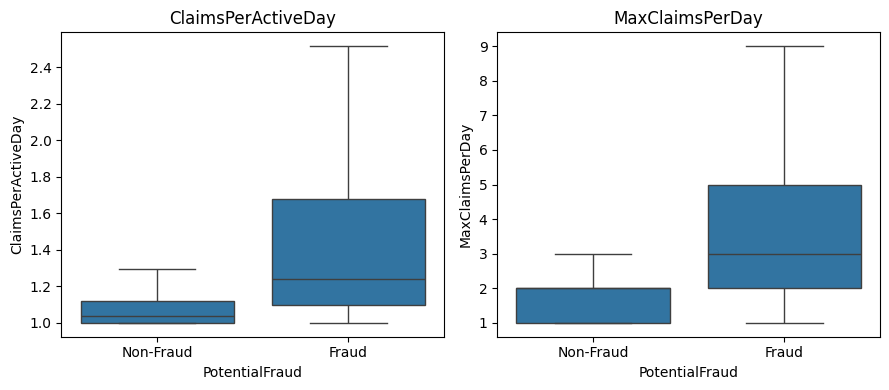

In [51]:
fraud_boxplots(['ClaimsPerActiveDay', 'MaxClaimsPerDay'])

*Fraud providers pack more claims into each active day — a burstiness signal distinct from raw claim count.*

## 10. Repeated / Suspicious Claims

In [52]:
provider_features[['SameBeneProviderDayRate', 'ClaimWithin7DaysRate', 'ClaimWithin30DaysRate']].describe()

,SameBeneProviderDayRate,ClaimWithin7DaysRate,ClaimWithin30DaysRate
count,5410.000000,5410.000000,5410.000000
mean,0.002081,0.108509,0.340272
std,0.009895,0.111880,0.168619
min,0.000000,0.000000,0.000000
25%,0.000000,0.050000,0.272727
50%,0.000000,0.101449,0.341679
75%,0.000000,0.137586,0.401764
max,0.285714,1.000000,1.000000


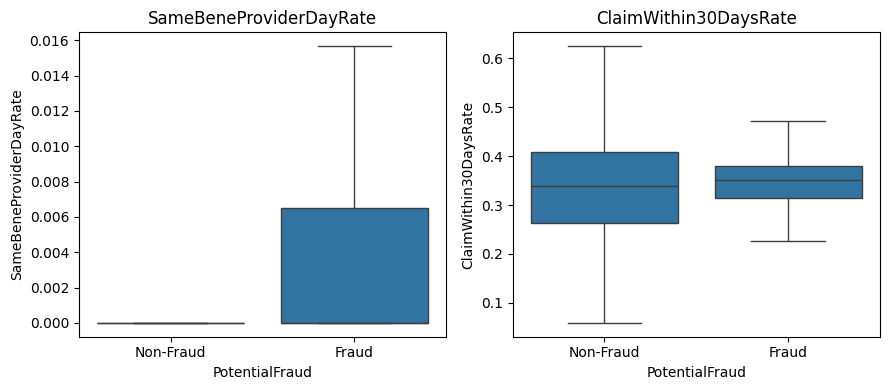

In [53]:
fraud_boxplots(['SameBeneProviderDayRate', 'ClaimWithin30DaysRate'])

*Rapid-repeat billing patterns (claims within 7/30 days of the same patient) — check whether these track fraud independently or just restate claim volume/beneficiary count.*

## 11. Feature Distributions (Consolidated)

A side-by-side view across categories, for features that looked most separated above.

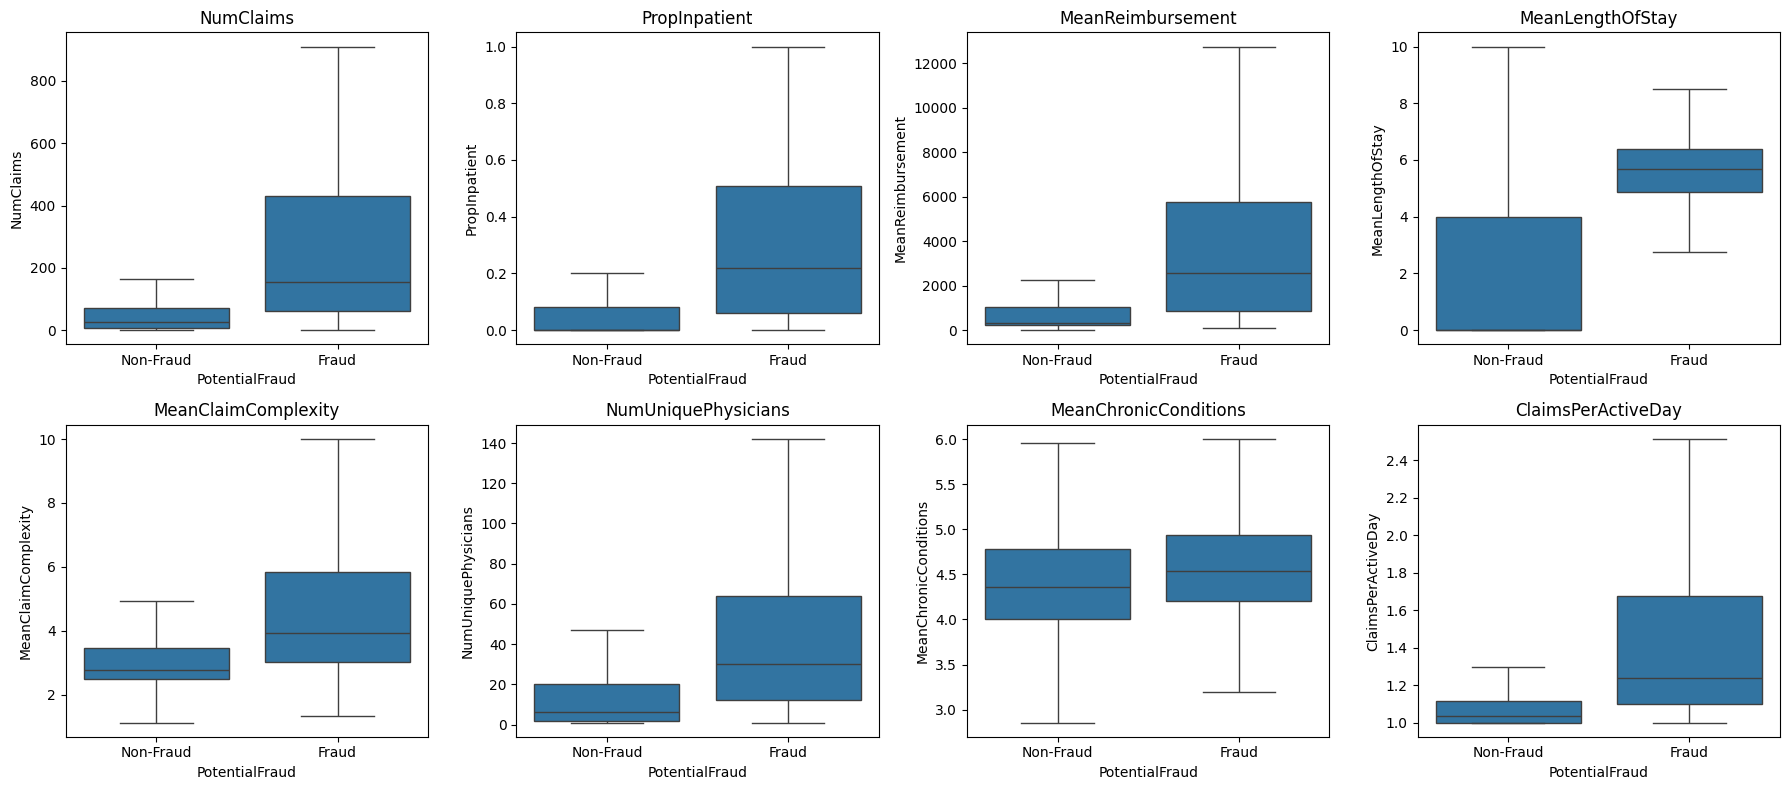

In [54]:
highlight_features = [
    'NumClaims', 'PropInpatient', 'MeanReimbursement', 'MeanLengthOfStay',
    'MeanClaimComplexity', 'NumUniquePhysicians', 'MeanChronicConditions', 'ClaimsPerActiveDay',
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, highlight_features):
    sns.boxplot(data=provider_features, x='PotentialFraud', y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Non-Fraud', 'Fraud'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

*Visually, claim volume and reimbursement show the cleanest separation; patient-complexity features look the closest to overlapping.*

## 12. Feature Relationships

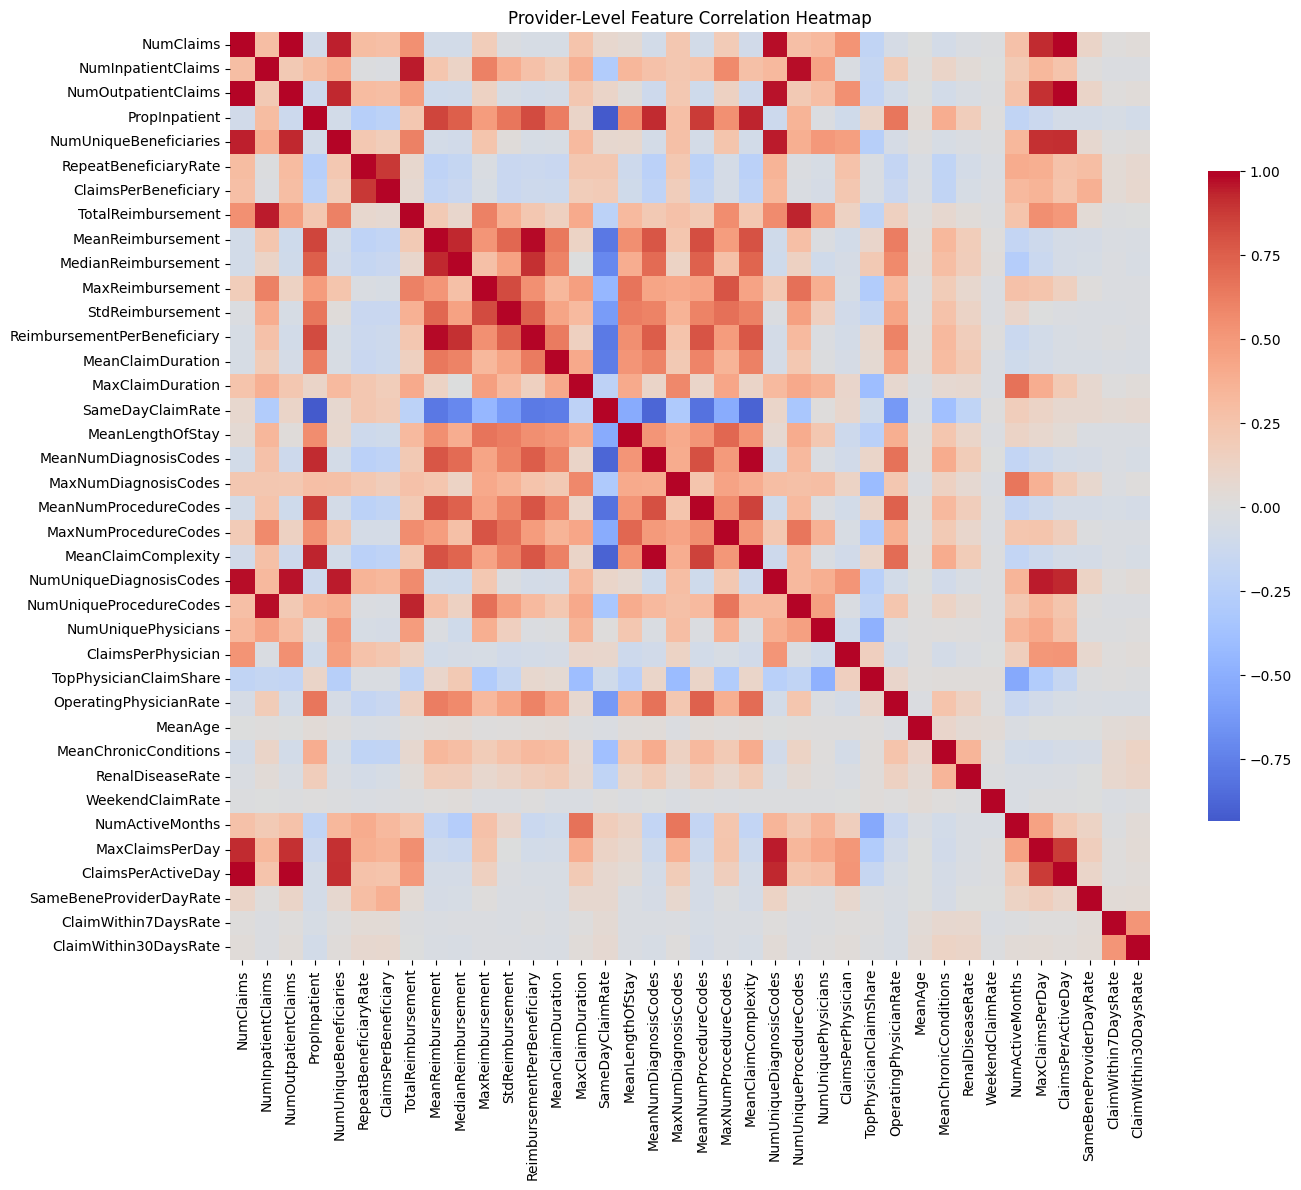

In [55]:
feature_cols = [c for c in provider_features.columns if c not in ('Provider', 'PotentialFraud')]
corr = provider_features[feature_cols].corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink': 0.7})
ax.set_title('Provider-Level Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

*Look for tight clusters (e.g. the various reimbursement statistics, or claim-volume-adjacent counts) — those are the multicollinearity groups Step 4's VIF elimination will need to resolve before logistic regression.*

In [56]:
fraud_corr = provider_features[feature_cols + ['PotentialFraud']].corr()['PotentialFraud'].drop('PotentialFraud').sort_values(key=abs, ascending=False)
fraud_corr

TotalReimbursement             0.575558
NumUniqueProcedureCodes        0.564768
NumInpatientClaims             0.525393
MaxReimbursement               0.514671
MaxNumProcedureCodes           0.453090
NumUniqueDiagnosisCodes        0.400036
MaxClaimsPerDay                0.393555
NumUniqueBeneficiaries         0.393531
MaxClaimDuration               0.375310
NumClaims                      0.374197
StdReimbursement               0.347964
ClaimsPerActiveDay             0.347388
NumOutpatientClaims            0.335803
MeanLengthOfStay               0.308969
NumUniquePhysicians            0.286703
MaxNumDiagnosisCodes           0.235075
ReimbursementPerBeneficiary    0.223880
PropInpatient                  0.205683
NumActiveMonths                0.204865
SameDayClaimRate              -0.196112
MeanReimbursement              0.193803
MeanClaimComplexity            0.193740
MeanNumDiagnosisCodes          0.189909
MeanNumProcedureCodes          0.188194
TopPhysicianClaimShare        -0.166905


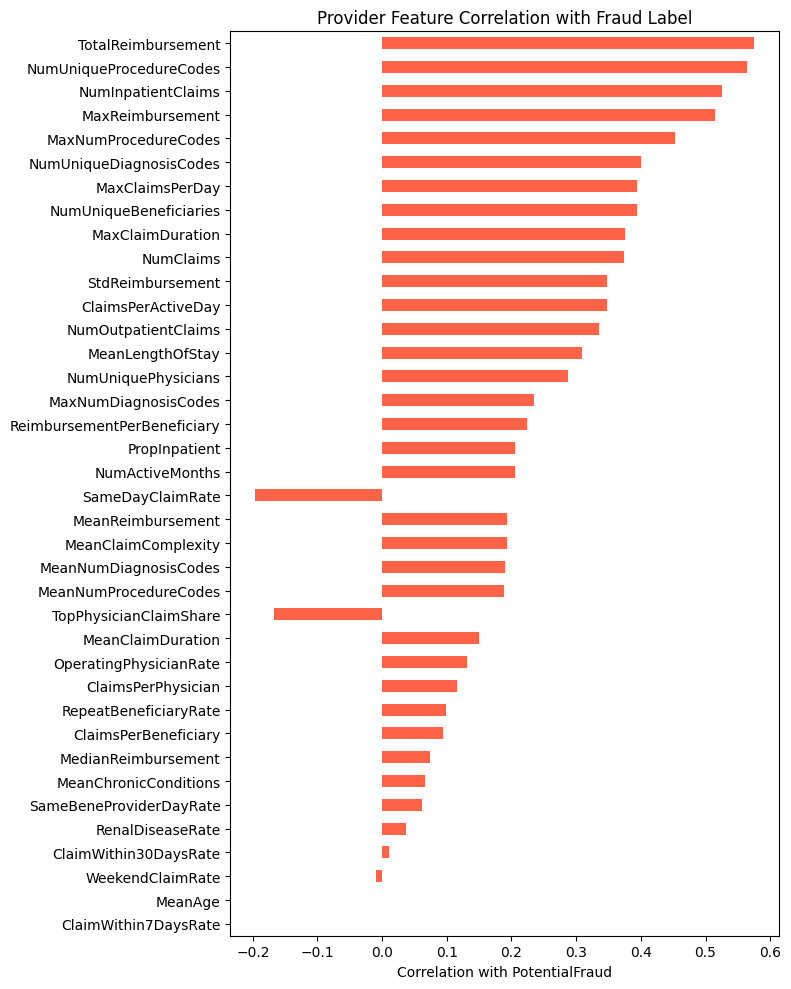

In [57]:
fig, ax = plt.subplots(figsize=(8, 10))
fraud_corr.plot(kind='barh', ax=ax, color='tomato')
ax.invert_yaxis()
ax.set_xlabel('Correlation with PotentialFraud')
ax.set_title('Provider Feature Correlation with Fraud Label')
plt.tight_layout()
plt.show()

*Ranked promising-predictor scan — treat this as a first pass (linear correlation only); pair with the proper Cohen's d / VIF check the Extended Candidate Features section and `04b_feature_engineering.ipynb` already do for the `src/features.py` feature set, before finalizing which of these to model with.*

## Summary

### Statistical testing (original Step 3)

- **Strongest signals:** `TotalClaimAmt` and `NumClaims` (provider-level claim
  volume/amount) — both show meaningful separation between Fraud and
  Non-Fraud groups, both visually and statistically (Cohen's d ≈ 0.64-0.67).
- **Moderate signal:** `ClaimType` (Inpatient vs Outpatient) — Inpatient
  claims show a notably higher fraud rate (Cramér's V = 0.11).
- **Weak/no signal:** `AvgNumPhysicians`, `AvgAgeAtClaim` — little to no
  separation between groups on their own.
- **Benford's Law (aggregate level):** not a strong discriminator once
  sample-size effects are corrected for (MAD: 0.0186 fraud vs. 0.0181
  non-fraud) — worth reporting as tested-but-inconclusive, not omitted.
- **Watch for multicollinearity:** `AvgClaimAmt` and `PropInpatient` are
  highly correlated (0.84) — consider this when selecting features in Step 4.

### Extended candidate features

Ranked by |Cohen's d| against `PotentialFraud` (n=5,410 providers). Several
results **reversed the initial hypothesis** — fraud providers show *more*
diverse diagnosis/procedure coding and *less* dependence on any single
"super-patient," not more repetitive "templated" billing as originally
hypothesized. 5 candidates were strong enough to add to `src/features.py`
(`TopProcedureCodeShare`, `TopBeneficiaryClaimShare`, `TopDiagnosisCodeShare`,
`BenfordMAD`, `AvgPhysicianProviderSpread`); `RoundNumberClaimRate` looked
strong (d=0.68) but turned out to correlate 0.99 with the existing
`PropInpatient` — a false lead caught by the redundancy check, not added.

### Broader provider-level EDA (38-feature table)

- **Target**: 9.35% of providers (506/5,410) are labeled fraudulent.
- **Top correlates**: `TotalReimbursement` (0.58), `NumUniqueProcedureCodes`
  (0.56), `NumInpatientClaims` (0.53), `MaxReimbursement` (0.51) — volume/amount
  dominates, consistent with the statistical testing above.
- **Caveat**: `NumUniqueDiagnosisCodes` correlates 0.97 with `NumClaims` — it's
  restating claim volume, not measuring code diversity. `TopDiagnosisCodeShare`/
  `TopProcedureCodeShare` above (concentration ratios, not raw counts) are the
  more trustworthy version of this signal.
- **"Breadth not concentration" confirmed independently**: `RepeatBeneficiaryRate`
  is higher for fraud (0.215 vs. 0.152) while `TopBeneficiaryClaimShare` above
  is lower — fraud providers see more beneficiaries more than once, but no
  single beneficiary dominates. Same pattern for physicians:
  `NumUniquePhysicians` up, `TopPhysicianClaimShare` down.
- **Patient complexity doesn't explain the billing gap**: `MeanAge` is
  essentially identical between groups (73.20 vs. 73.21).
- **Honest negative finding**: despite the "detect repeated billing patterns"
  framing, `SameBeneProviderDayRate` and `ClaimWithin30DaysRate` are both
  essentially flat between fraud and non-fraud — tested, not discriminative.

### Bottom line

Claim volume and billing amount are the workhorses across every angle tested
here — claim-level stats, candidate features, and the broader 38-feature
table all converge on the same conclusion. The main open question for Step 4
is resolving the "breadth not concentration" pattern (spread across many
physicians/beneficiaries/codes rather than depending on a few) into clean,
non-redundant model features, since several raw-count versions of this idea
(`NumUniqueDiagnosisCodes`, `NumUniquePhysicians`) are volume-confounded in
ways their concentration-ratio counterparts are not.